# FSK and BPSK: baseline CNN diagnostics

Inspect the **original CNN b8 / BCE / lr=0.0003 baseline only**. For each family, choose the highest- and lowest-false-negative-rate validation recording/antenna from the saved baseline results. These deliberately selected examples are not representative averages. Only examples with labeled RFI are eligible.

Show measured power, truth and detector flags, following the reference notebook. Native-resolution errors, score distributions and power distributions help investigate where misses occur, but cannot establish a physical cause on their own. This model predicts binary RFI, not the family name.

Requires NumPy, matplotlib, PyTorch and IPython. Uses saved validation thresholds; no training or test tuning. The family-balanced checkpoint is not loaded or used.


In [1]:
from pathlib import Path
import os, tempfile
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'rfi-diagnostic-mpl'))
import json, csv, io, zipfile
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'cs163-rfi-starter-v1.0/data/starter-v1.0/dataset.csv').is_file())
DATA = ROOT/'cs163-rfi-starter-v1.0/data/starter-v1.0'
ARCHIVE = ROOT/'Week2/grid_20261020T045116Z_selina_cnn_b8_18f27e4b-20261025T223801Z-1-001.zip'
OUT = ROOT/'Week3/fsk_bpsk_diagnostics'
OUT.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(1)
plt.rcParams.update({'font.size':9, 'axes.spines.top':False, 'axes.spines.right':False})
def save(fig,name):
    fig.savefig(OUT/(name+'.png'),dpi=160,bbox_inches='tight')
    display(Image(filename=str(OUT/(name+'.png'))))
    plt.close(fig)
def show_table(rows,fields):
    def fmt(v): return f'{v:.4f}' if isinstance(v,float) else str(v)
    display(Markdown('| '+' | '.join(fields)+' |\n|'+'|'.join(['---']*len(fields))+'|\n'+
                     '\n'.join('| '+' | '.join(fmt(r[k]) for k in fields)+' |' for r in rows)))


In [2]:
class DoubleConv(nn.Module):
    def __init__(self, incoming, outgoing):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(incoming, outgoing, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(outgoing, outgoing, 3, padding=1), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.layers(x)


class SegmentationModel(nn.Module):
    """Same b8 no-skip CNN and state-dict names as the Week2 baseline."""
    def __init__(self):
        super().__init__()
        self.enc1 = DoubleConv(1, 8)
        self.enc2 = DoubleConv(8, 16)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(16, 32)
        self.up2 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec2 = DoubleConv(16, 16)
        self.up1 = nn.ConvTranspose2d(16, 8, 2, stride=2)
        self.dec1 = DoubleConv(8, 8)
        self.output = nn.Conv2d(8, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        z = self.bottleneck(self.pool(e2))
        return self.output(self.dec1(self.up1(self.dec2(self.up2(z)))))




In [3]:
# Load only the supplied, trusted checkpoints; no ZIP extraction is needed.
with zipfile.ZipFile(ARCHIVE) as z:
    prefix=next(n[:-len('best.pt')] for n in z.namelist() if n.endswith('/bce_lr0.0003/best.pt'))
    bc=torch.load(io.BytesIO(z.read(prefix+'best.pt')),map_location='cpu',weights_only=False)
    calibration=json.loads(z.read(prefix+'calibration.json'))
    evaluation=next(n[:-len('per_antenna.csv')] for n in z.namelist()
                    if n.startswith(prefix+'evaluation_validation_') and n.endswith('/per_antenna.csv'))
    rows=list(csv.DictReader(io.StringIO(z.read(evaluation+'per_antenna.csv').decode())))
import hashlib
assert hashlib.sha256((DATA/'dataset.csv').read_bytes()).hexdigest()==bc['config']['catalog_sha256']
MODELS={}
for name,ck,cut in [('Baseline',bc,calibration['quantized_cut'])]:
    model=SegmentationModel().to(DEVICE)
    model.load_state_dict(ck['model_state_dict']);model.eval()
    MODELS[name]=dict(model=model,cut=cut,normalization=ck['normalization'])
with (DATA/'dataset.csv').open() as f:catalog={int(r['sample_id']):r for r in csv.DictReader(f)}
selected=[]
for family in ['fsk','bpsk']:
    eligible=[r for r in rows if r['method']=='model_matched_clean_fpr' and r['rfi_type']==family and int(r['tp'])+int(r['fn'])>0]
    eligible.sort(key=lambda r:(int(r['fn'])/(int(r['tp'])+int(r['fn'])),int(r['sample_id']),int(r['antenna'])))
    for label,row in [('Highest false negative rate',eligible[-1]),('Lowest false negative rate',eligible[0])]:
        selected.append(dict(family=family,selection=label,sample_id=int(row['sample_id']),antenna=int(row['antenna'])))
print('Selected examples (by false negative rate; ties resolved by recording and antenna):')
show_table(selected,['family','selection','sample_id','antenna'])

examples=[];metrics=[]
for info in selected:
    record=catalog[info['sample_id']]
    assert record['split']=='validation'
    folder=DATA/record['path'];a=info['antenna']
    raw=np.load(folder/'power.npy',mmap_mode='r')[:,a,:,0].astype(np.float32)
    truth=np.unpackbits(np.load(folder/'rfi_mask.npy',mmap_mode='r')[:,a,:,0],axis=1,count=128).astype(bool)
    metadata=json.loads((folder/'recording.json').read_text())
    example=dict(**info,raw=raw,truth=truth,metadata=metadata,predictions={})
    for name,setting in MODELS.items():
        norm=setting['normalization'];x=torch.from_numpy((raw-norm['mean'])/norm['std'])[None,None].to(DEVICE)
        with torch.inference_mode():p=setting['model'](x).sigmoid()[0,0].cpu().numpy()
        flags=np.floor(p.astype(np.float64)*65535).astype(np.int64)>=setting['cut']
        tp=int((flags&truth).sum());fp=int((flags&~truth).sum());fn=int((~flags&truth).sum());tn=int((~flags&~truth).sum())
        result=dict(**info,model=name,tp=tp,fp=fp,fn=fn,tn=tn,false_negative_rate_percent=100*fn/(tp+fn),
                    recall=tp/(tp+fn),precision=tp/(tp+fp) if tp+fp else 0.,fpr=fp/(fp+tn))
        if name=='Baseline':
            saved=next(r for r in rows if r['method']=='model_matched_clean_fpr' and int(r['sample_id'])==info['sample_id'] and int(r['antenna'])==a)
            differences={k:result[k]-int(saved[k]) for k in ['tp','fp','fn','tn']}
            print('Baseline count differences versus saved GPU evaluation:', info['sample_id'], a, differences)
            if max(abs(v) for v in differences.values()) > 100:
                raise ValueError('Large inference mismatch; inspect checkpoint and preprocessing before plotting')
        metrics.append(result);example['predictions'][name]=dict(p=p,flags=flags)
    examples.append(example)
show_table(metrics,['family','selection','model','sample_id','antenna','fn','false_negative_rate_percent','fpr'])
with (OUT/'selected_example_metrics.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(metrics[0]));writer.writeheader();writer.writerows(metrics)


| family | selection | sample_id | antenna |
|---|---|---|---|
| fsk | Highest false negative rate | 125 | 9 |
| fsk | Lowest false negative rate | 126 | 6 |
| bpsk | Highest false negative rate | 113 | 5 |
| bpsk | Lowest false negative rate | 115 | 7 |

| family | selection | model | sample_id | antenna | fn | false_negative_rate_percent | fpr |
|---|---|---|---|---|---|---|---|
| fsk | Highest false negative rate | Baseline | 125 | 9 | 784 | 100.0000 | 0.0099 |
| fsk | Lowest false negative rate | Baseline | 126 | 6 | 7630 | 59.5071 | 0.0200 |
| bpsk | Highest false negative rate | Baseline | 113 | 5 | 798 | 100.0000 | 0.0194 |
| bpsk | Lowest false negative rate | Baseline | 115 | 7 | 5389 | 36.2018 | 0.0322 |

Selected examples (by false negative rate; ties resolved by recording and antenna):
Baseline count differences versus saved GPU evaluation: 125 9 {'tp': 0, 'fp': 0, 'fn': 0, 'tn': 0}
Baseline count differences versus saved GPU evaluation: 126 6 {'tp': 0, 'fp': 0, 'fn': 0, 'tn': 0}
Baseline count differences versus saved GPU evaluation: 113 5 {'tp': 0, 'fp': 0, 'fn': 0, 'tn': 0}
Baseline count differences versus saved GPU evaluation: 115 7 {'tp': 0, 'fp': 0, 'fn': 0, 'tn': 0}


## Full-recording views: three different color scales

All three panels use time (ms) horizontally and frequency channel vertically. Each display pixel averages **16 consecutive time samples**, about 0.524 ms. This averaging is for display only.

1. **Measured power:** the mean stored power value in that bin. Units are stored power counts, not probability. The color range is set by the 99.5th percentile for that example, so its maximum can differ between figures. Higher values are clipped in color only.
2. **Target mask (0–1):** the fraction of those 16 native samples labeled RFI. A value of 1 means all 16 are RFI; 0.5 means 8 of 16; 0 means none.
3. **Detector flags (0–1):** the fraction of those 16 samples flagged after thresholding the model at the saved validation cutoff. A value of 0.5 means 8 of 16 are flagged; it is **not 50% model confidence**.

The target and flag fractions do not establish that exactly the same native pixels coincide. Use the native-resolution error maps to distinguish detected RFI, misses and false flags.


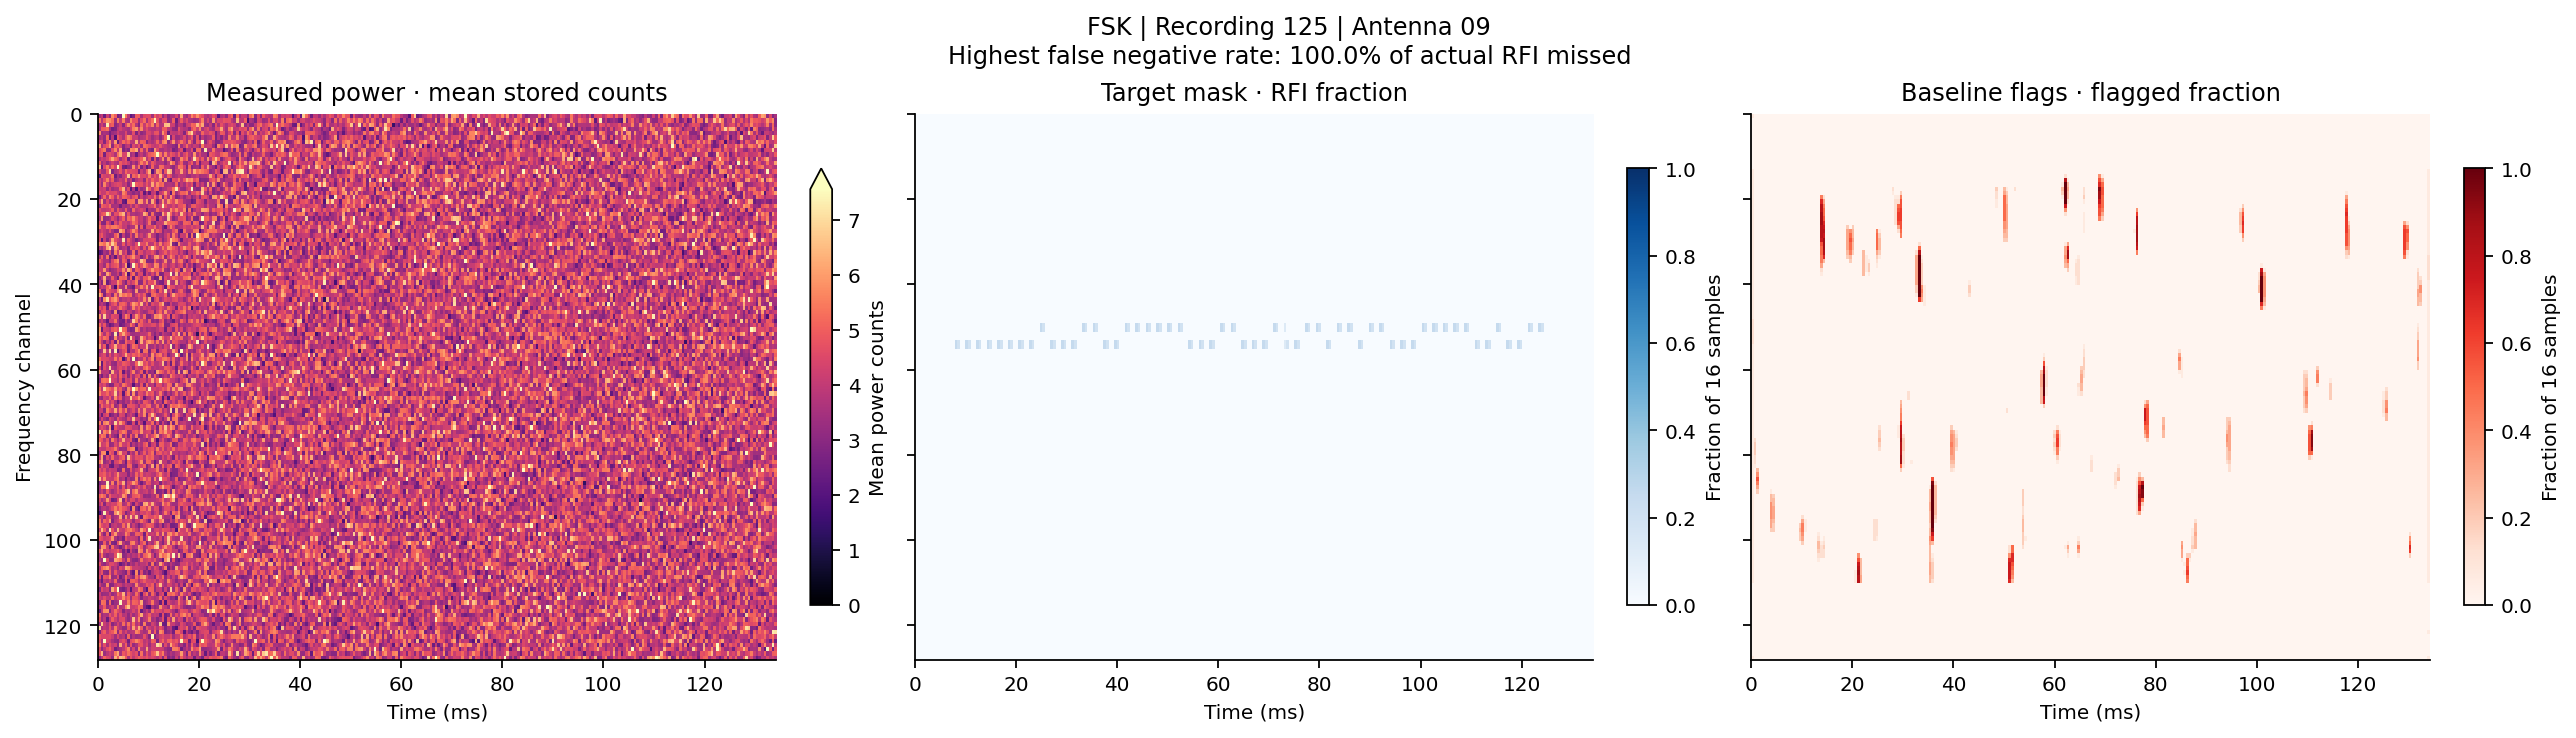

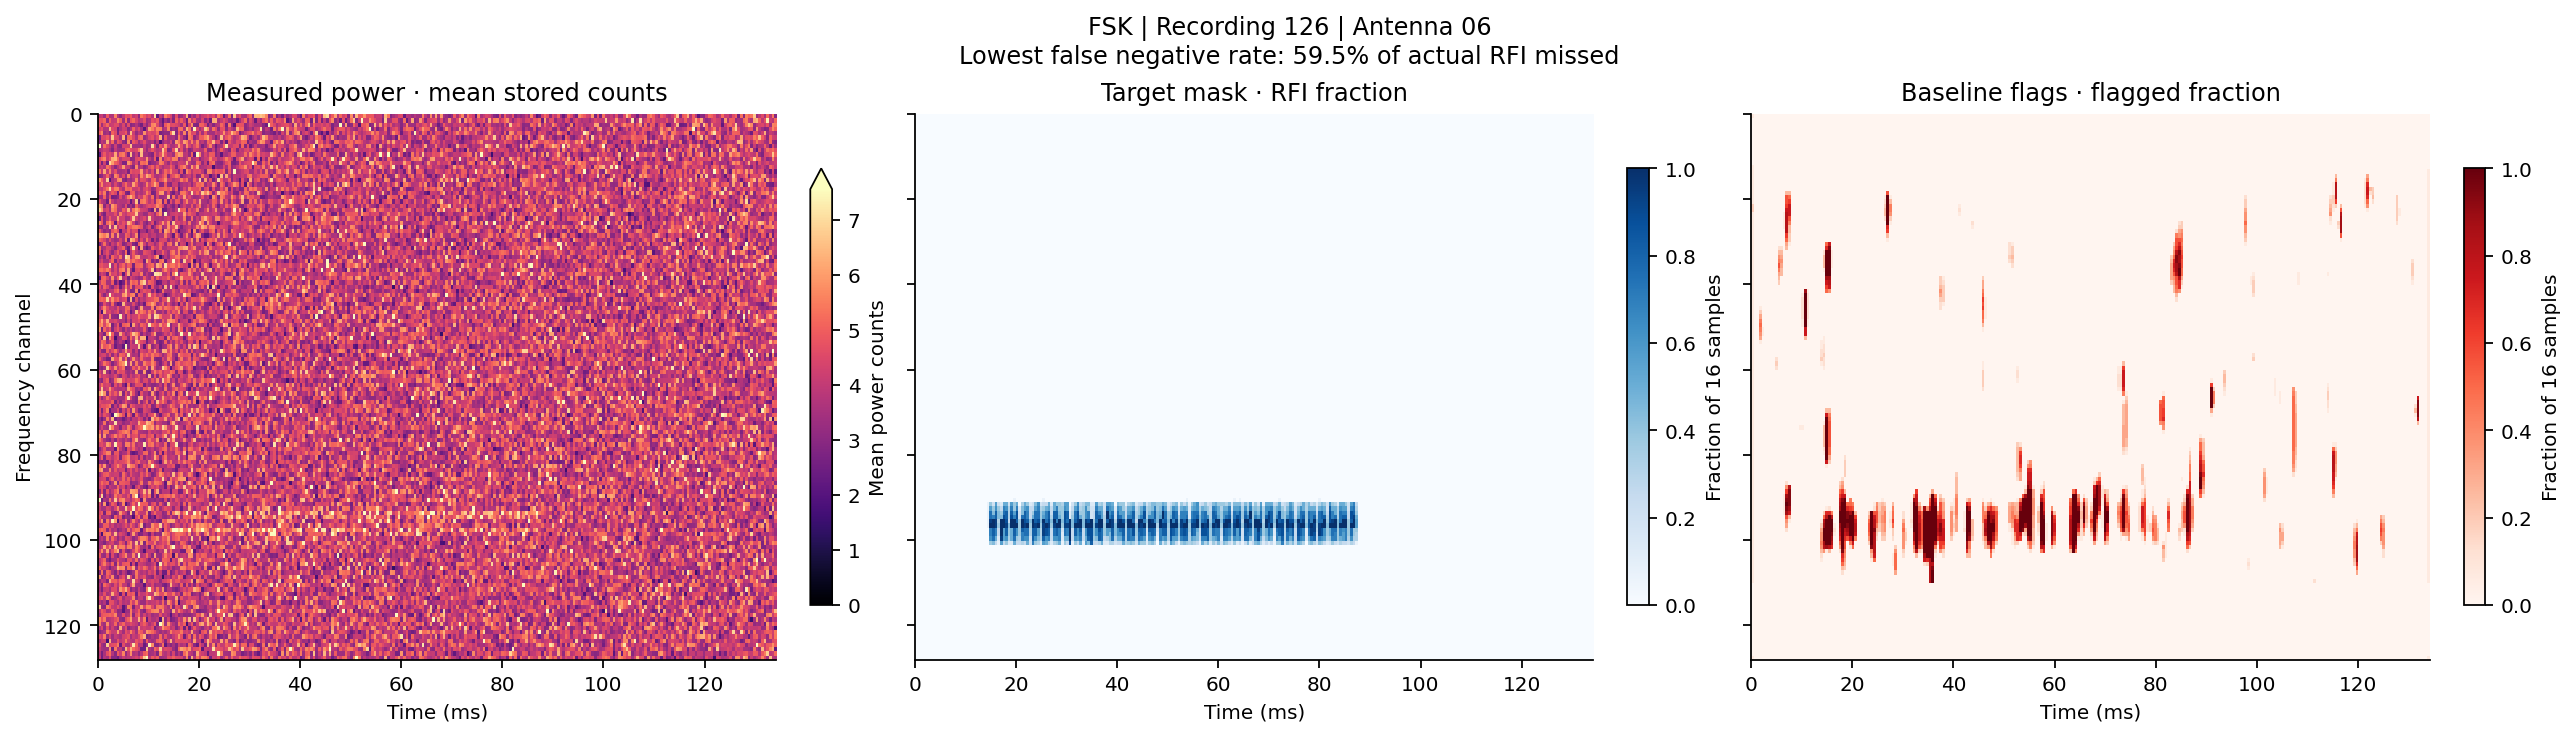

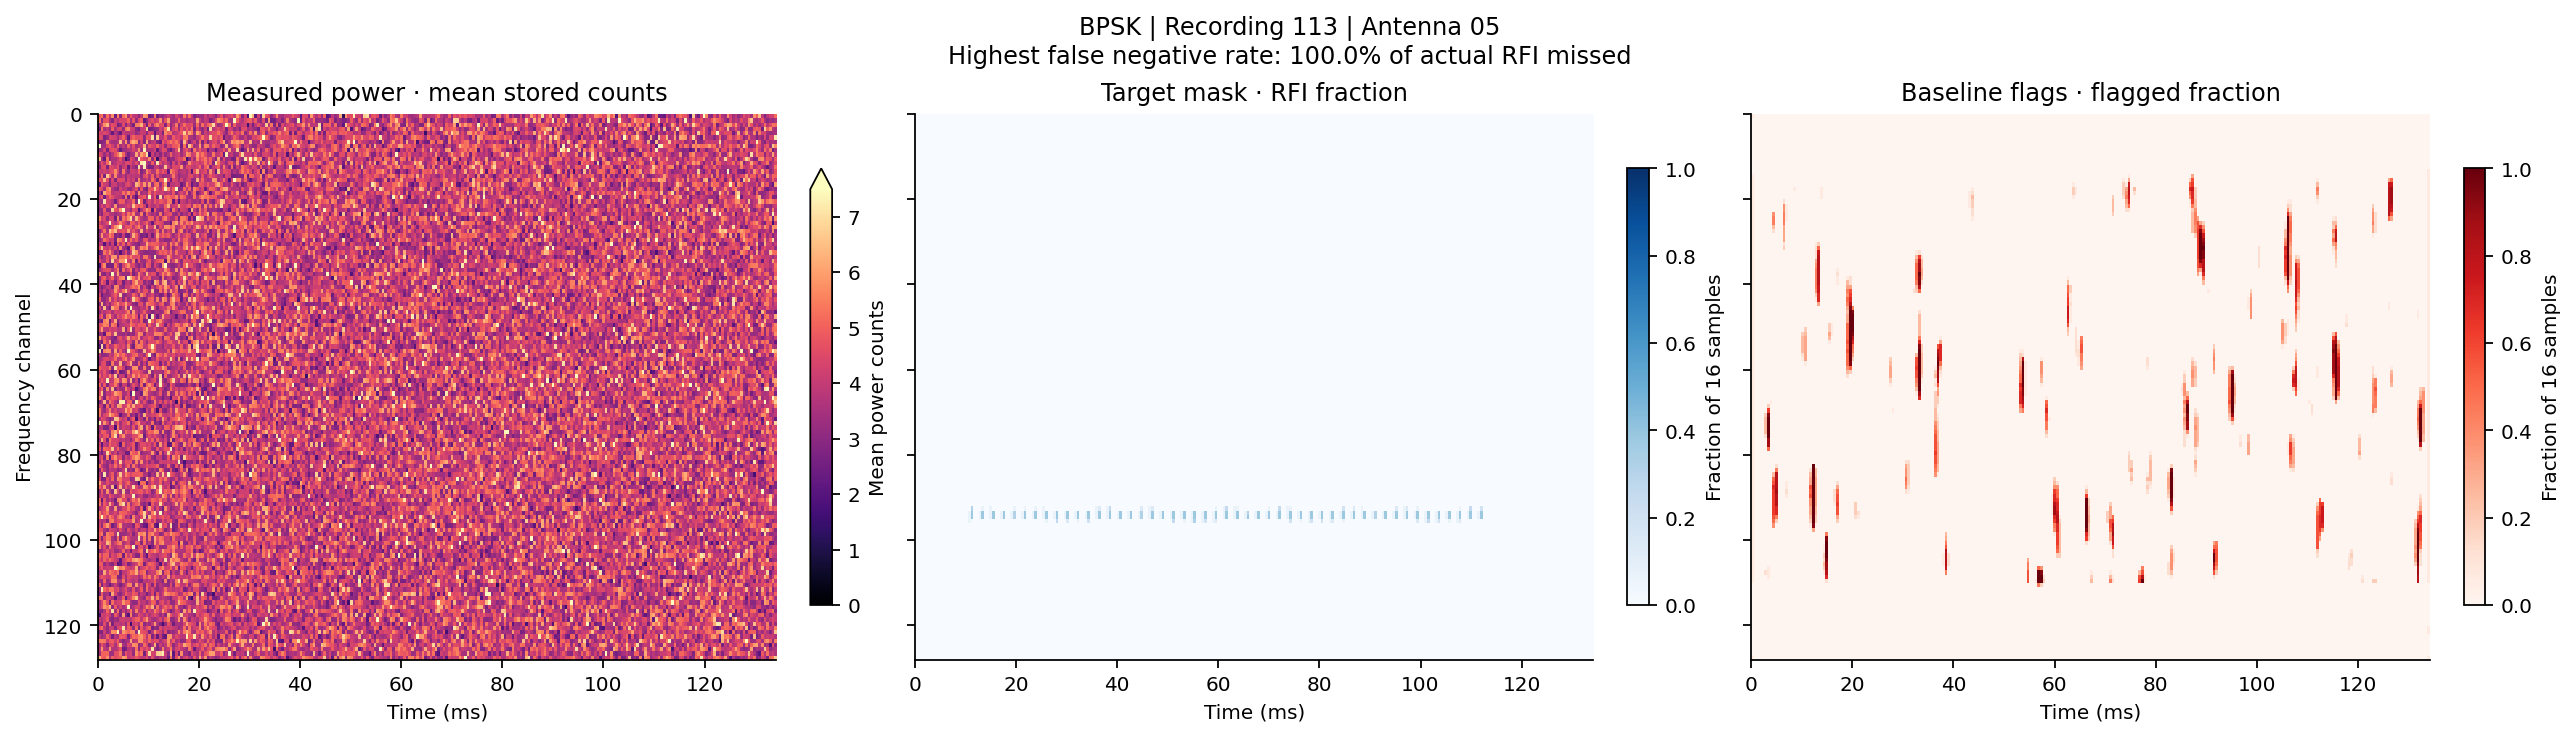

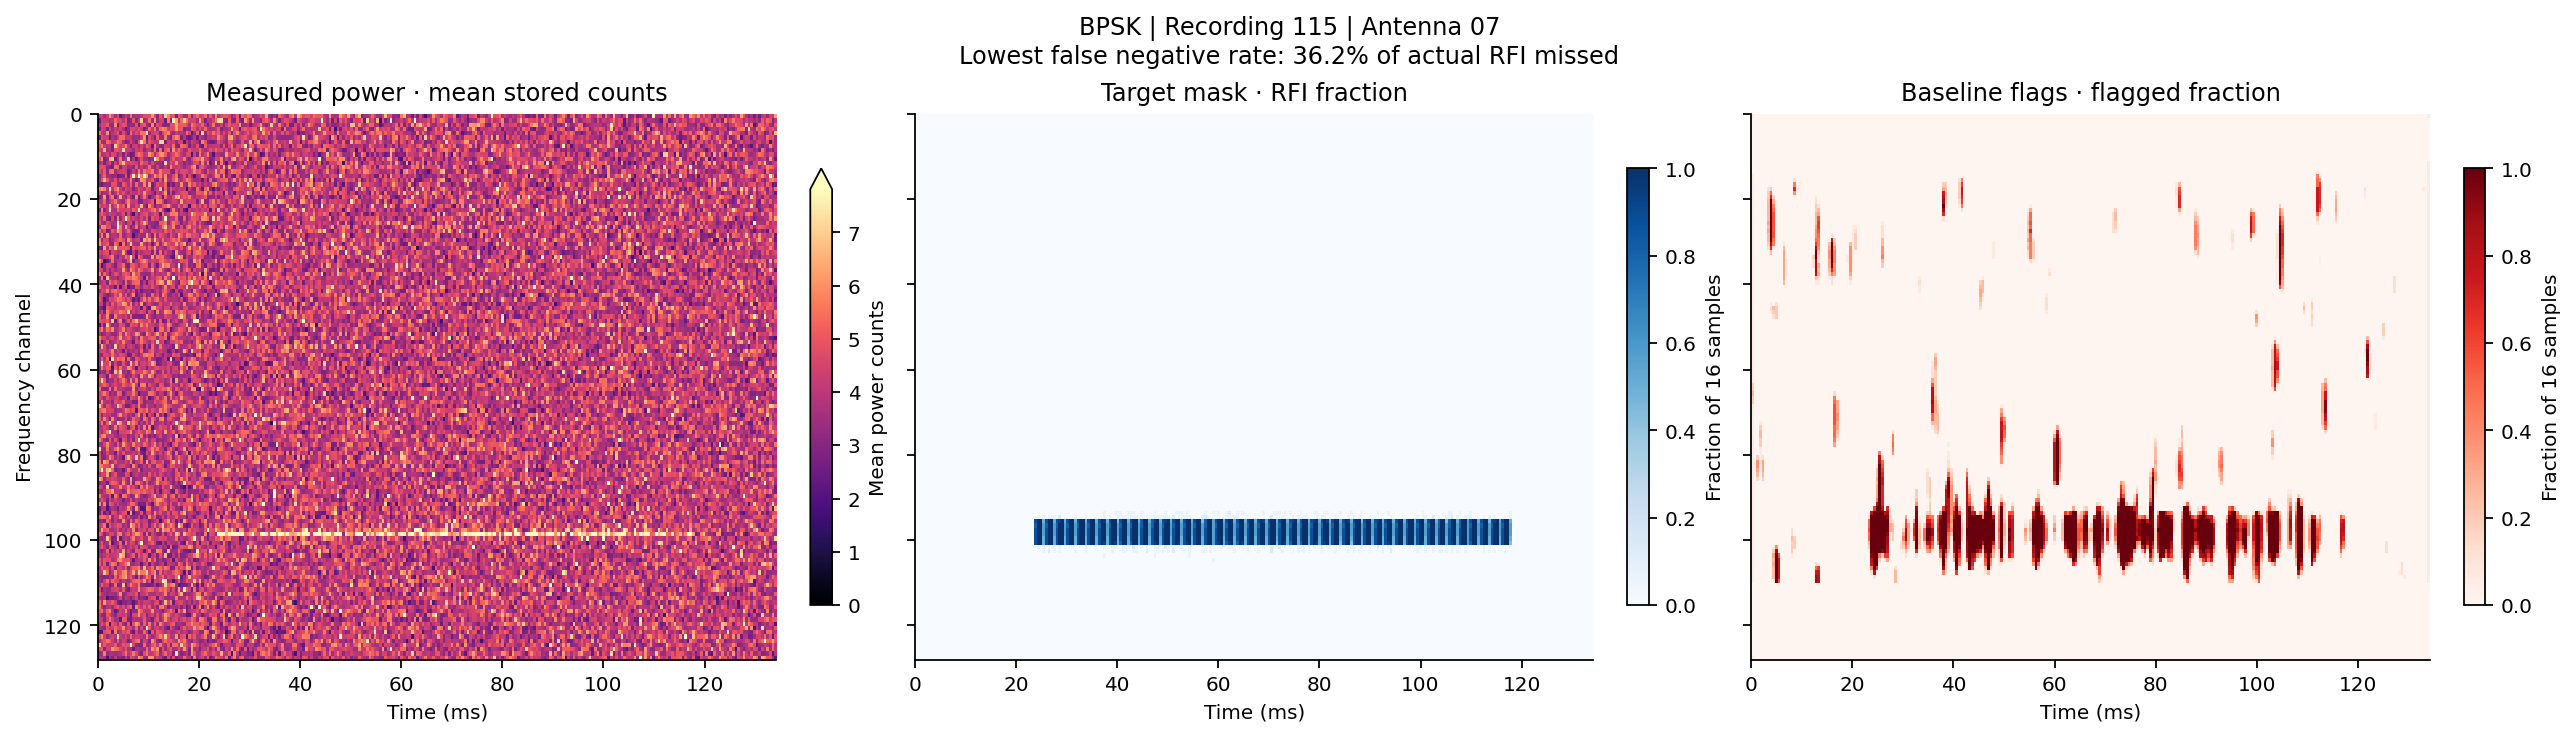

In [4]:
def average(x,factor=16):return x.reshape(-1,factor,x.shape[1]).mean(axis=1)
for e in examples:
    dt=e['metadata']['dt_s'];extent=[0,len(e['raw'])*dt*1000,128,0]
    fig,axes=plt.subplots(1,3,figsize=(16,4.5),sharex=True,sharey=True,layout='constrained')
    pred=e['predictions']['Baseline']
    views=[average(e['raw']),average(e['truth']),average(pred['flags'])]
    titles=['Measured power · mean stored counts','Target mask · RFI fraction','Baseline flags · flagged fraction']
    vmax=np.quantile(views[0],.995)
    for j,(view,title) in enumerate(zip(views,titles)):
        im=axes[j].imshow(view.T,aspect='auto',origin='upper',extent=extent,interpolation='nearest',
                          cmap=['magma','Blues','Reds'][j],vmin=0,vmax=vmax if j==0 else 1)
        axes[j].set_title(title);axes[j].set_xlabel('Time (ms)')
        fig.colorbar(im,ax=axes[j],shrink=.8,label='Mean power counts' if j==0 else 'Fraction of 16 samples',
                     extend='max' if j==0 else 'neither')
    axes[0].set_ylabel('Frequency channel')
    selected_metric=next(r for r in metrics if r['sample_id']==e['sample_id'] and r['antenna']==e['antenna'])
    fig.suptitle(f"{e['family'].upper()} | Recording {e['sample_id']} | Antenna {e['antenna']:02d}\n{e['selection']}: {selected_metric['false_negative_rate_percent']:.1f}% of actual RFI missed")
    save(fig,f"{e['family']}_{e['sample_id']}_a{e['antenna']}_overview")


## Native-resolution zooms and their scales

Select the 256-sample window containing the most RFI pixels missed by the baseline (or most truth pixels if no misses). Crop frequency around truth channels with padding. This deliberately highlights a failure region, not typical performance. No averaging is applied.

- **Power:** native stored counts, with the color maximum set to this crop's 99.5th percentile.
- **Score / cutoff (0–3 color range):** sigmoid score divided by the saved cutoff (~0.02725). A ratio of 1 is the decision boundary; 0.5 is half the cutoff, not 50% probability. Ratios above 3 share the top color. Detection uses the exact saved integer quantization rule.
- **Errors:** categorical colors for true negative, detected RFI, missed RFI and false flag. These are category labels, not a continuous numeric measurement.


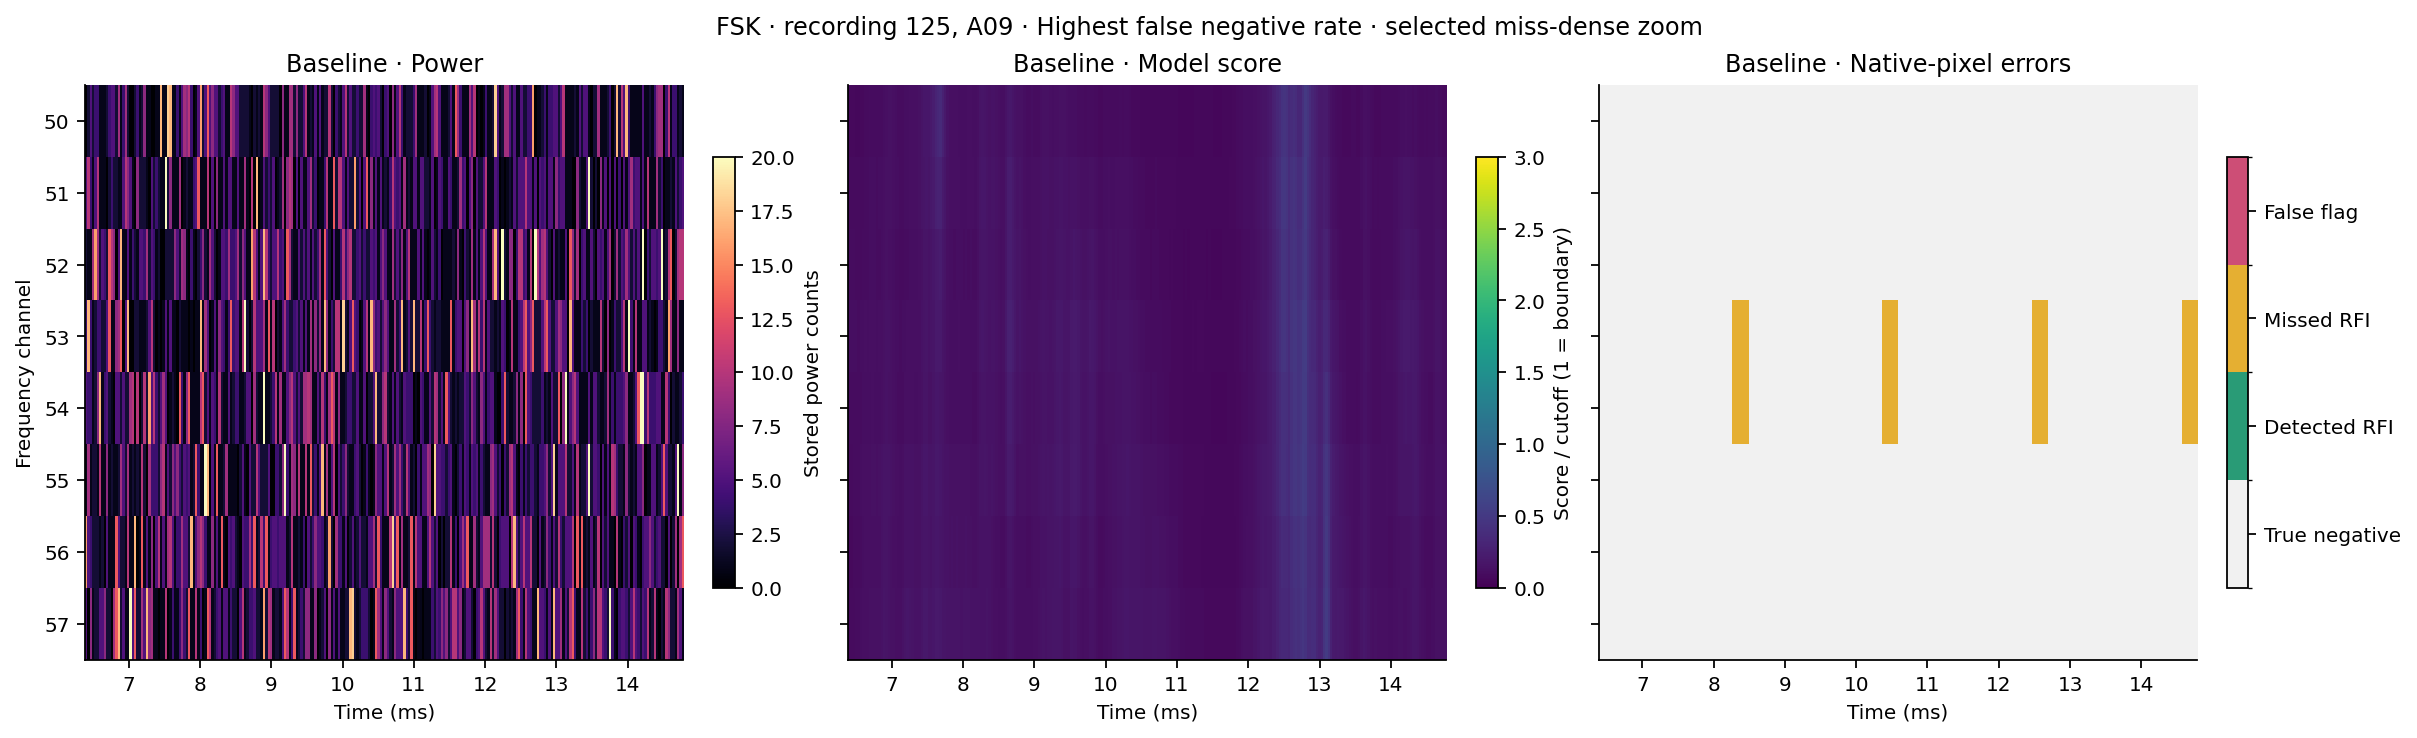

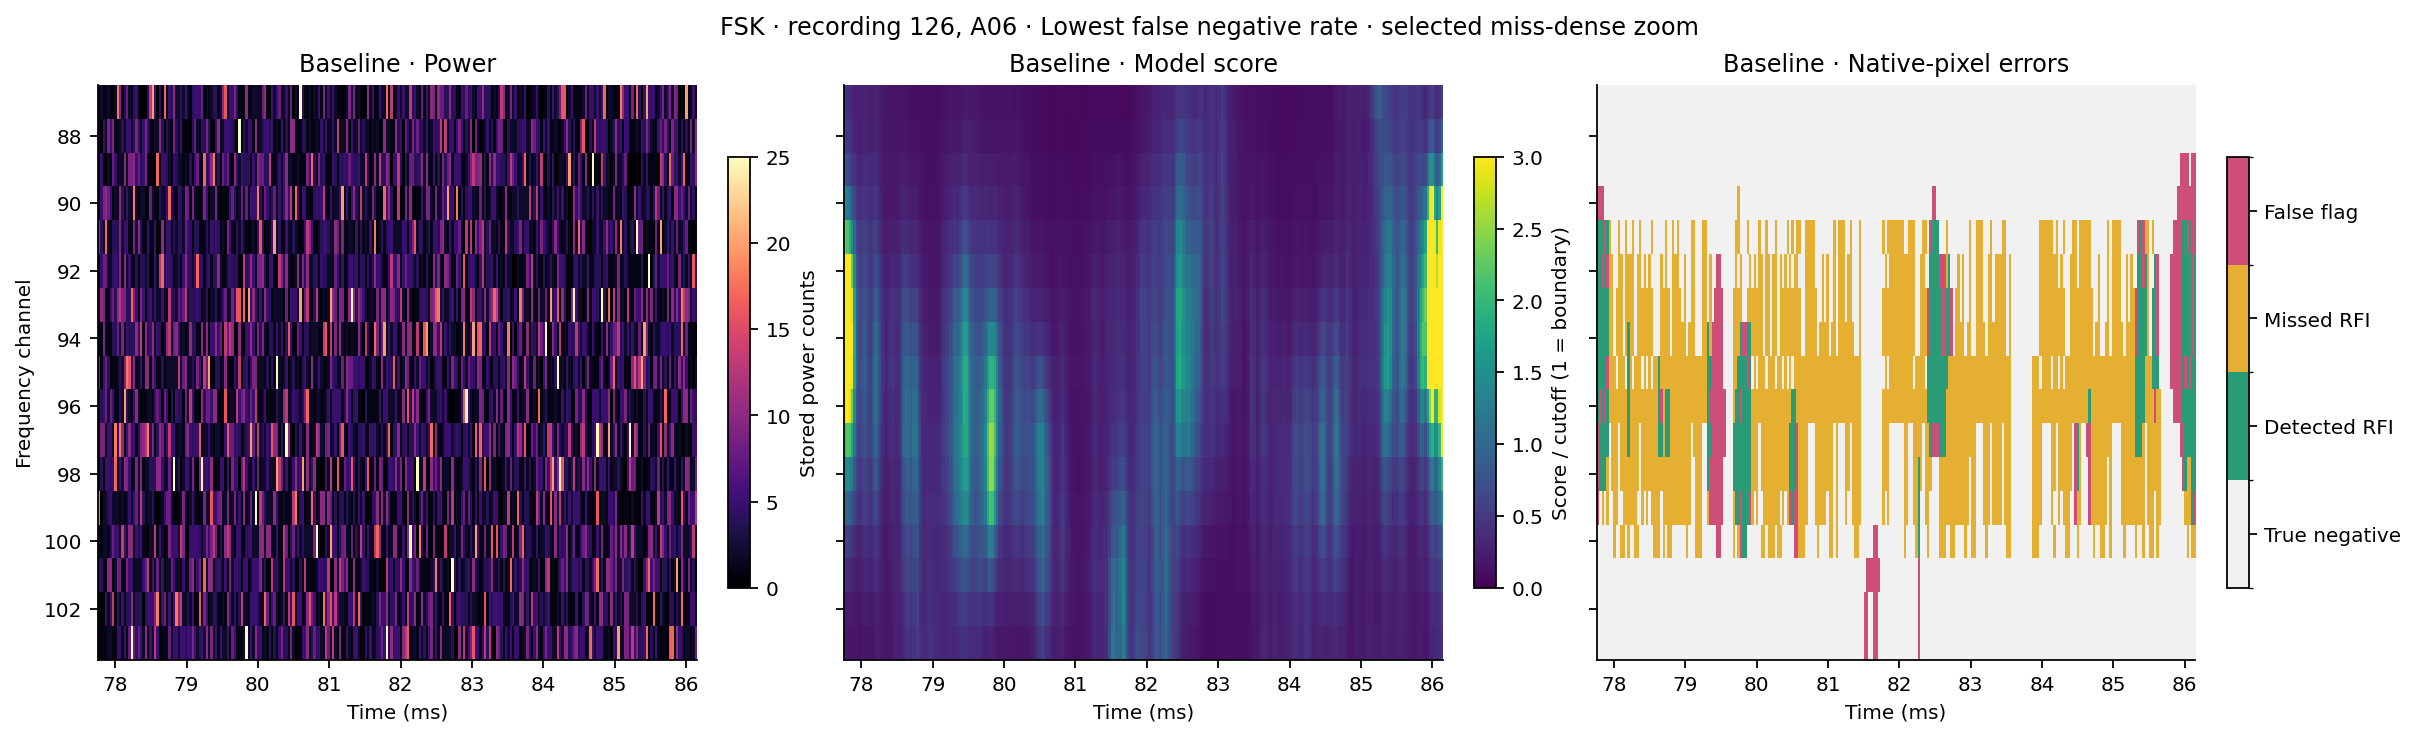

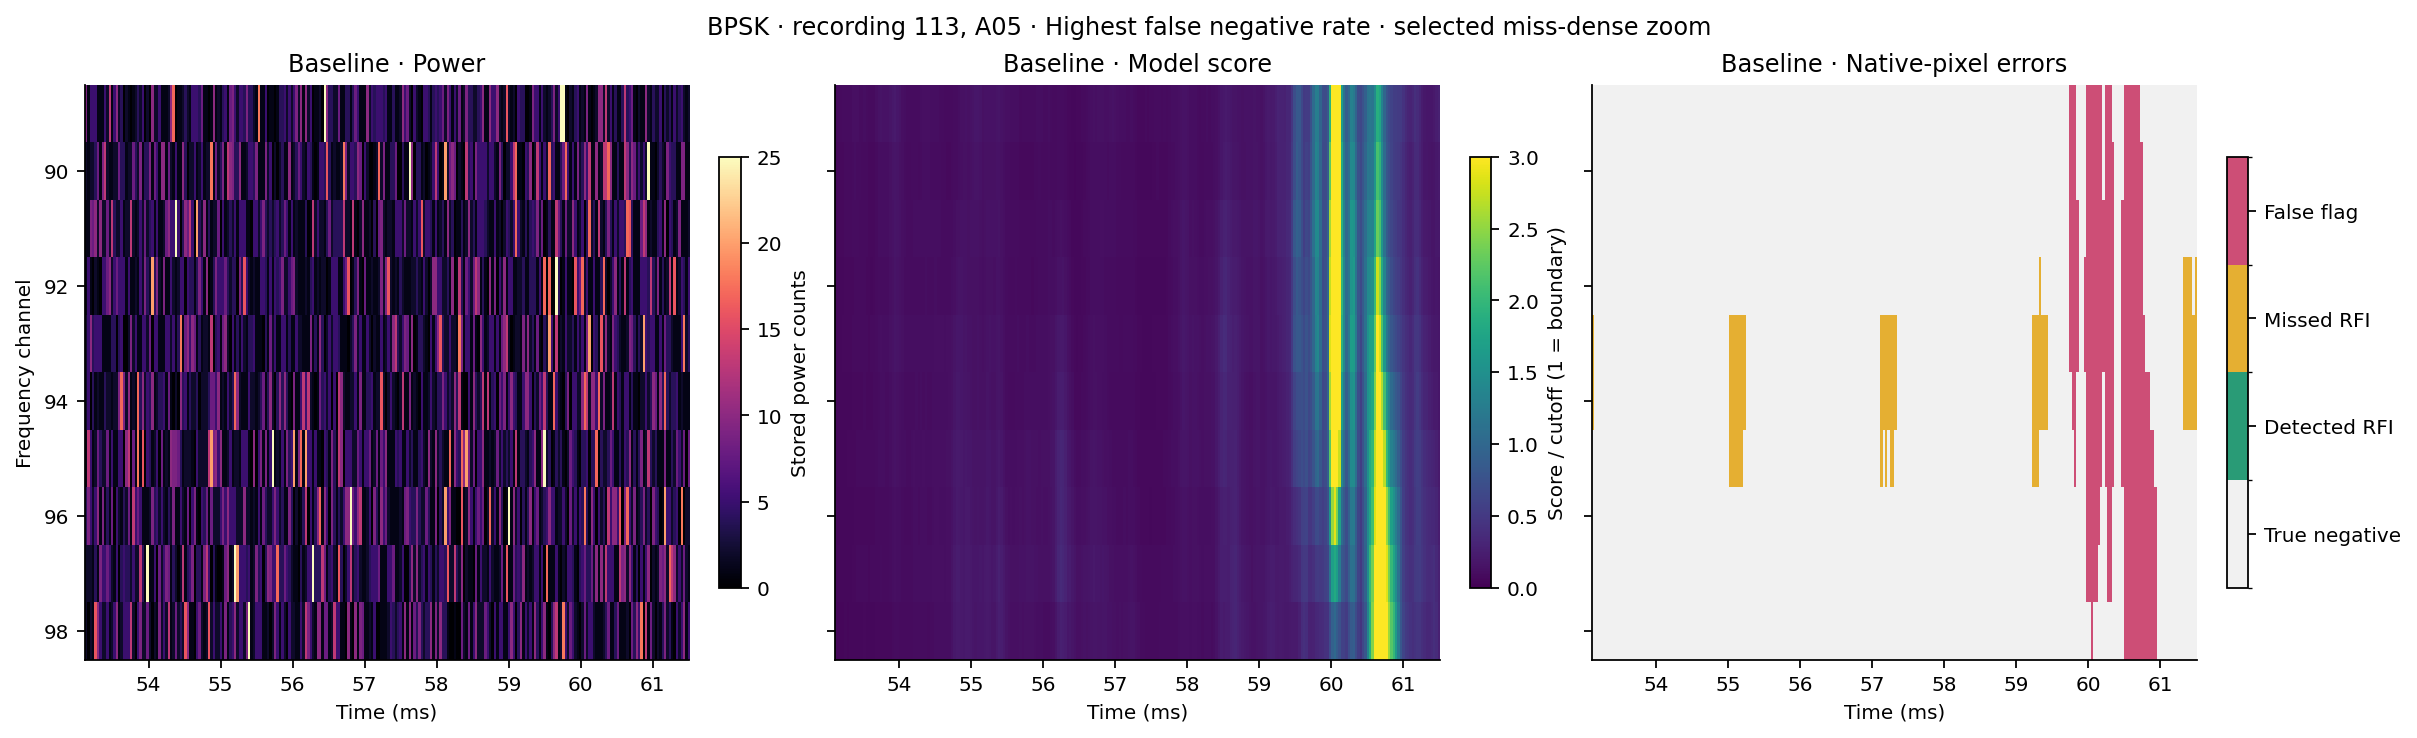

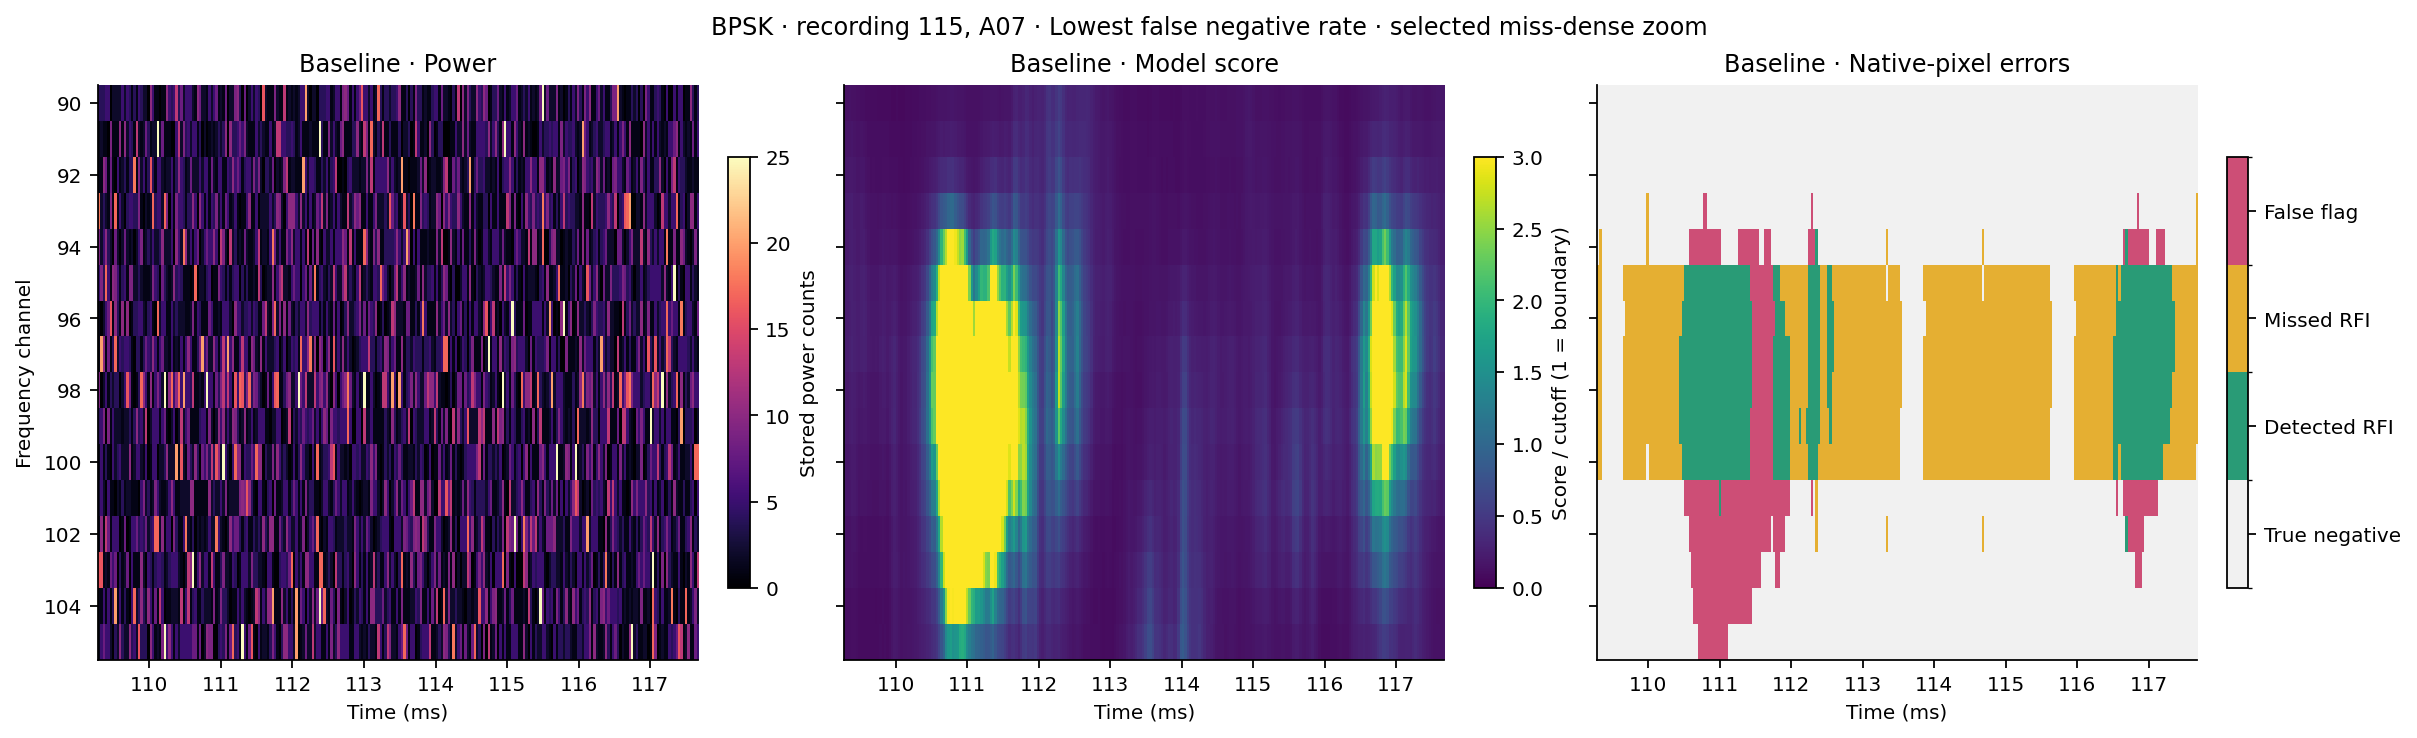

In [5]:
error_colors=ListedColormap(['#f1f1f1','#299b76','#e5af32','#cd4e76'])
for e in examples:
    truth=e['truth'];miss=truth & ~e['predictions']['Baseline']['flags']
    target=miss if miss.any() else truth
    length=256
    totals=np.convolve(target.sum(axis=1),np.ones(length,dtype=int),mode='valid')
    start=int(totals.argmax());stop=start+length
    channels=np.flatnonzero(truth[start:stop].any(axis=0))
    lo=max(0,int(channels.min())-3);hi=min(128,int(channels.max())+4)
    sl=np.s_[start:stop,lo:hi];dt=e['metadata']['dt_s']
    extent=[start*dt*1000,stop*dt*1000,hi-.5,lo-.5]
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),squeeze=False,sharex=True,sharey=True,layout='constrained')
    vmax=np.quantile(e['raw'][sl],.995)
    for i,(name,pred) in enumerate(e['predictions'].items()):
        flags=pred['flags'];codes=np.zeros(truth.shape,dtype=np.uint8)
        codes[truth&flags]=1;codes[truth&~flags]=2;codes[~truth&flags]=3
        im=axes[i,0].imshow(e['raw'][sl].T,extent=extent,aspect='auto',cmap='magma',vmin=0,vmax=vmax,interpolation='nearest')
        fig.colorbar(im,ax=axes[i,0],label='Stored power counts',shrink=.75)
        im=axes[i,1].imshow((pred['p'][sl]/(MODELS[name]['cut']/65535)).T,extent=extent,aspect='auto',cmap='viridis',vmin=0,vmax=3,interpolation='nearest')
        fig.colorbar(im,ax=axes[i,1],label='Score / cutoff (1 = boundary)',shrink=.75)
        im=axes[i,2].imshow(codes[sl].T,extent=extent,aspect='auto',cmap=error_colors,norm=BoundaryNorm(np.arange(-.5,4.5),4),interpolation='nearest')
        cb=fig.colorbar(im,ax=axes[i,2],ticks=range(4),shrink=.75)
        cb.ax.set_yticklabels(['True negative','Detected RFI','Missed RFI','False flag'])
        for j,title in enumerate(['Power','Model score','Native-pixel errors']):
            axes[i,j].set_title(name+' · '+title);axes[i,j].set_xlabel('Time (ms)')
        axes[i,0].set_ylabel('Frequency channel')
    fig.suptitle(f"{e['family'].upper()} · recording {e['sample_id']}, A{e['antenna']:02d} · {e['selection']} · selected miss-dense zoom")
    save(fig,f"{e['family']}_{e['sample_id']}_a{e['antenna']}_native_errors")


## Score and power distributions

Score histograms use a logarithmic x-axis showing score divided by the baseline cutoff. RFI to the left of 1 is missed; background to the right of 1 is falsely flagged. The y-axis is the fraction of pixels in each logarithmic bin, normalized separately for RFI and background.

Power histograms compare detected RFI, missed RFI and background. Their x-axis uses stored power counts; the log-scaled y-axis is the separately normalized fraction in each one-count bin. Neither distribution uses a 0–1 confidence scale. Both pool only the two selected examples per family. Distribution overlap is descriptive, not proof that detection is impossible.


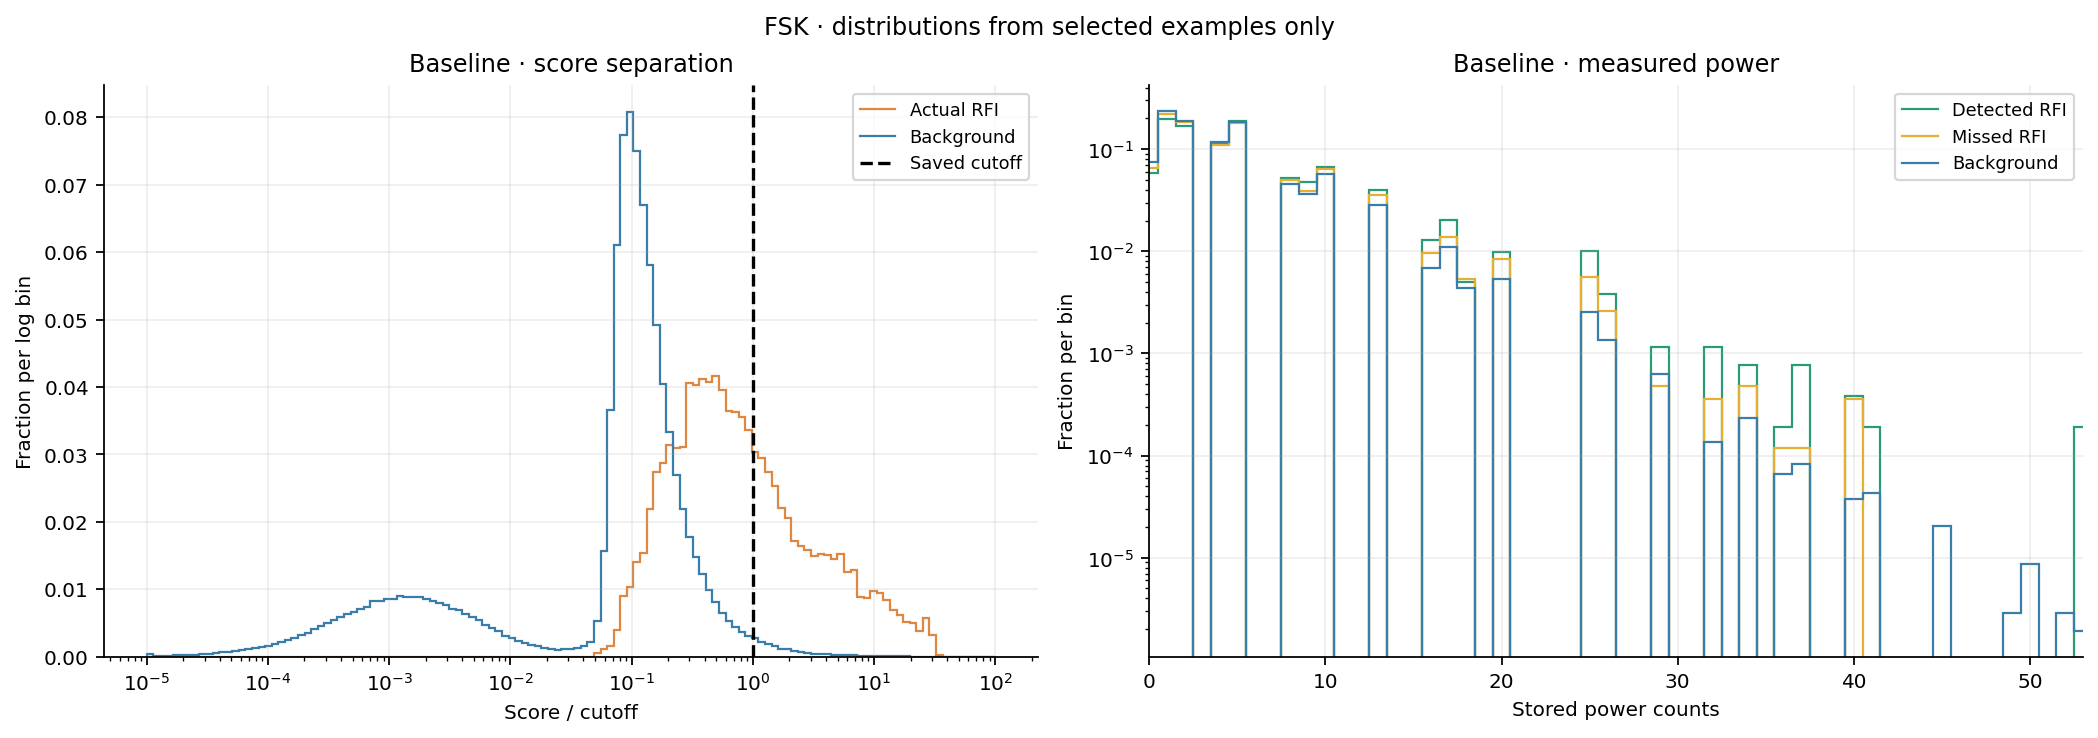

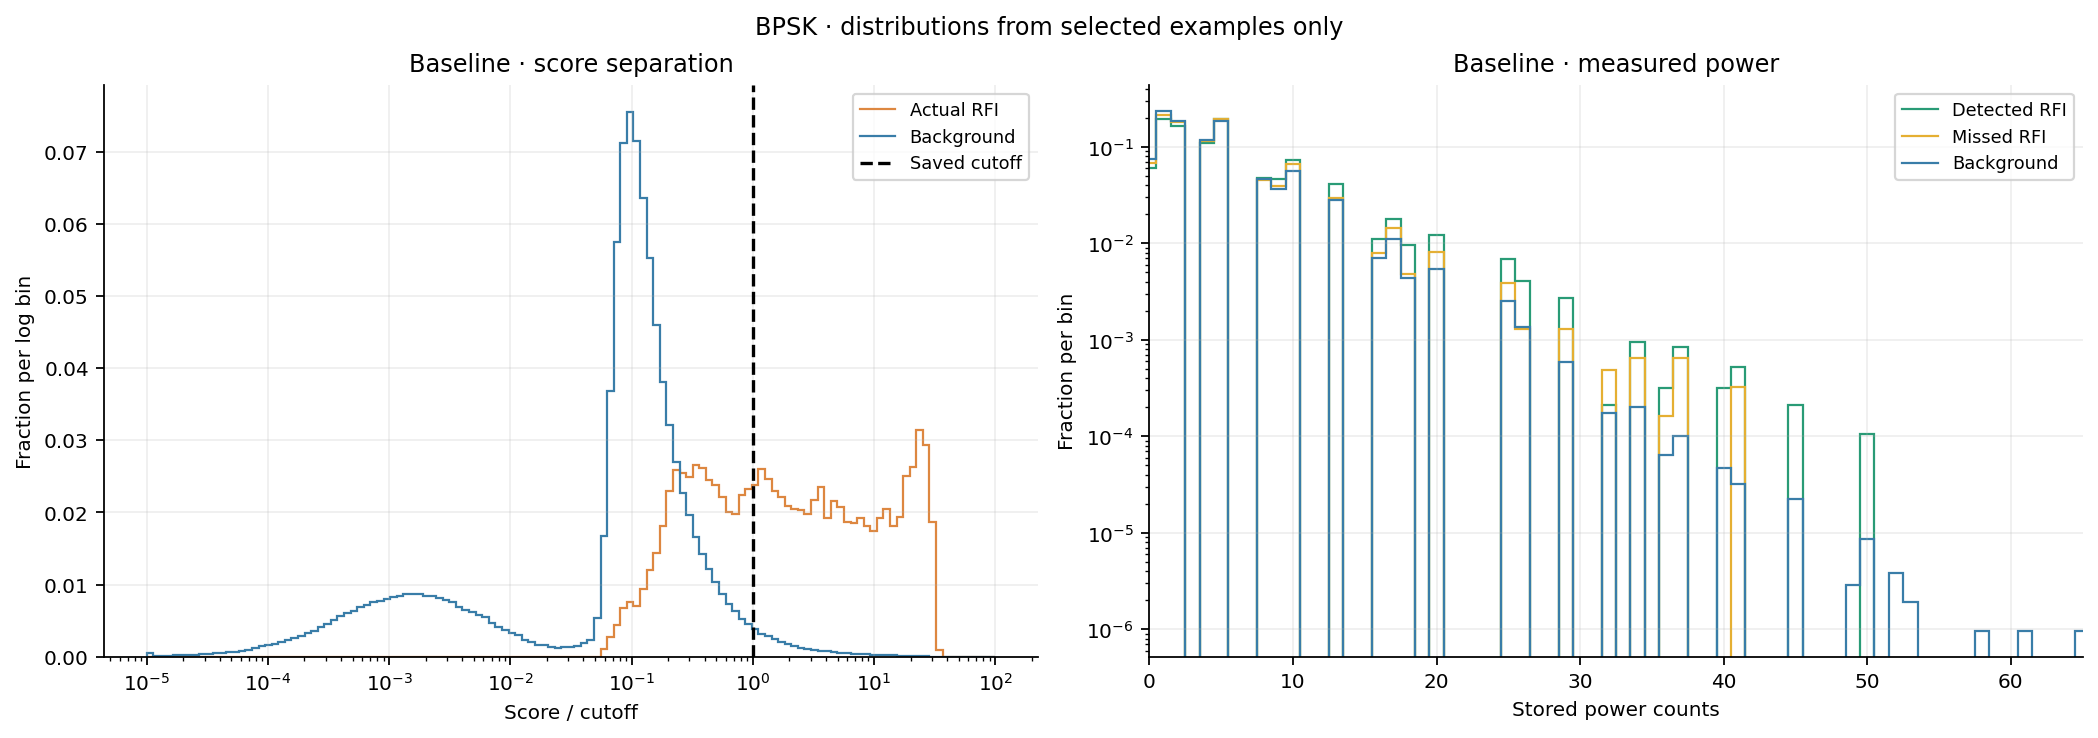

In [6]:
score_bins=np.geomspace(1e-5,100,130)
power_bins=np.arange(-.5,256.5,1)
for family in ['fsk','bpsk']:
    chosen=[e for e in examples if e['family']==family]
    fig,axes=plt.subplots(1,2,figsize=(13,4.5),squeeze=False,layout='constrained')
    for i,name in enumerate(MODELS):
        rfi=[];background=[];caught_power=[];missed_power=[];bg_power=[]
        for e in chosen:
            truth=e['truth'];pred=e['predictions'][name];flags=pred['flags']
            relative=pred['p']/(MODELS[name]['cut']/65535)
            rfi.append(relative[truth]);background.append(relative[~truth])
            caught_power.append(e['raw'][truth&flags]);missed_power.append(e['raw'][truth&~flags]);bg_power.append(e['raw'][~truth])
        for values,label,color in [(rfi,'Actual RFI','#dd8740'),(background,'Background','#397da8')]:
            values=np.concatenate(values);counts,_=np.histogram(np.clip(values,score_bins[0],score_bins[-1]),score_bins)
            axes[i,0].stairs(counts/counts.sum(),score_bins,label=label,color=color)
        axes[i,0].axvline(1,color='black',ls='--',label='Saved cutoff')
        axes[i,0].set(xscale='log',xlabel='Score / cutoff',ylabel='Fraction per log bin',title=name+' · score separation')
        for values,label,color in [(caught_power,'Detected RFI','#299b76'),(missed_power,'Missed RFI','#e5af32'),(bg_power,'Background','#397da8')]:
            values=np.concatenate(values)
            if len(values):
                counts,_=np.histogram(values,power_bins)
                axes[i,1].stairs(counts/counts.sum(),power_bins,label=label,color=color)
        axes[i,1].set(xlabel='Stored power counts',ylabel='Fraction per bin',yscale='log',xlim=(0,max(20,max(float(e['raw'].max()) for e in chosen))),title=name+' · measured power')
        for ax in axes[i]:ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.suptitle(f'{family.upper()} · distributions from selected examples only')
    save(fig,family+'_score_power_distributions')


## Reading these diagnostics

- **Low scores on labeled structures:** the model misses their appearance at this operating point. A lower threshold may catch more but also increase false flags; inspect score overlap.
- **Missed-RFI power overlapping background:** weak contrast is a plausible contributor, but temporal/frequency structure may still provide information.
- **Power structures with no RFI label:** check the label definition and simulator settings before treating every bright pixel as mislabeled.
- **Time-averaged plots look blank:** use the native zoom before concluding that short events are absent.

Metrics are computed before display averaging. Native labels include the dataset's labeling limitations. The selected extremes and miss-dense crops cannot establish typical family behavior or causality; use all-recording diagnostics and multiple training seeds for stronger conclusions. Figures and example counts are saved under `Week3/fsk_bpsk_diagnostics/`.


## Interpreting the false negative comparison

**False negative rate = FN / (TP + FN)**: the percentage of actual RFI pixels the model misses. Lower is better. A value of 0% means all labeled RFI is detected; 100% means all is missed.

FSK and BPSK show one highest-rate and one lowest-rate example per family. Digital and carrier show one lowest-rate example each. These are selected extremes, not typical cases. Ties are ordered by recording ID and antenna; the highest-rate example uses the last tied entry and the lowest uses the first.

False negative rate does not penalize false alarms. Check the prediction maps and the separately reported FPR before concluding that a model is better overall. Metrics use native pixels before display averaging.


## One digital example and one carrier example

Digital and carrier are the baseline's two highest-AP validation families. Show **one example per family**, selected as that family's lowest recording–antenna false negative rate. These are favorable examples, not representative averages. The summary table uses all validation data; the plots use the selected recording and antenna only.

Read each figure from left to right: **observed power → true RFI labels → CNN predictions**. A display pixel averages 16 time samples. The blue and red color bars show the fraction of those samples labeled or flagged, respectively—not model confidence. A final figure places these same examples beside FSK and BPSK on a shared power scale.


In [7]:
with zipfile.ZipFile(ARCHIVE) as z:
    family_ap_rows=list(csv.DictReader(io.StringIO(z.read(evaluation+'model_pixel_AP_by_family.csv').decode())))
ranked_ap=sorted([(r['rfi_type'],float(r['pixel_ap_quantized'])) for r in family_ap_rows
                  if r['pixel_ap_quantized'] and np.isfinite(float(r['pixel_ap_quantized']))],
                 key=lambda pair:pair[1],reverse=True)
good_families=[f for f,ap in ranked_ap[:2]]
family_summary=[]
for family in ['fsk','bpsk']+good_families:
    family_rows=[r for r in rows if r['method']=='model_matched_clean_fpr' and r['rfi_type']==family]
    tp,fp,fn,tn=[sum(int(r[k]) for r in family_rows) for k in ['tp','fp','fn','tn']]
    family_summary.append(dict(family=family,ap=dict(ranked_ap)[family],false_negative_rate_percent=100*fn/(tp+fn),
                               precision=tp/(tp+fp),fpr=fp/(fp+tn)))
print('All-validation family metrics (not just selected examples):')
show_table(family_summary,['family','ap','false_negative_rate_percent','fpr'])
good_selected=[]
for family in good_families:
    eligible=[r for r in rows if r['method']=='model_matched_clean_fpr' and r['rfi_type']==family and int(r['tp'])+int(r['fn'])>0]
    eligible.sort(key=lambda r:(int(r['fn'])/(int(r['tp'])+int(r['fn'])),int(r['sample_id']),int(r['antenna'])))
    for label,row in [('Lowest false negative rate',eligible[0])]:
        good_selected.append(dict(family=family,selection=label,sample_id=int(row['sample_id']),antenna=int(row['antenna'])))
print('Selected good_examples (by false negative rate; ties resolved by recording and antenna):')
show_table(good_selected,['family','selection','sample_id','antenna'])

good_examples=[];good_metrics=[]
for info in good_selected:
    record=catalog[info['sample_id']]
    assert record['split']=='validation'
    folder=DATA/record['path'];a=info['antenna']
    raw=np.load(folder/'power.npy',mmap_mode='r')[:,a,:,0].astype(np.float32)
    truth=np.unpackbits(np.load(folder/'rfi_mask.npy',mmap_mode='r')[:,a,:,0],axis=1,count=128).astype(bool)
    metadata=json.loads((folder/'recording.json').read_text())
    example=dict(**info,raw=raw,truth=truth,metadata=metadata,predictions={})
    for name,setting in MODELS.items():
        norm=setting['normalization'];x=torch.from_numpy((raw-norm['mean'])/norm['std'])[None,None].to(DEVICE)
        with torch.inference_mode():p=setting['model'](x).sigmoid()[0,0].cpu().numpy()
        flags=np.floor(p.astype(np.float64)*65535).astype(np.int64)>=setting['cut']
        tp=int((flags&truth).sum());fp=int((flags&~truth).sum());fn=int((~flags&truth).sum());tn=int((~flags&~truth).sum())
        result=dict(**info,model=name,tp=tp,fp=fp,fn=fn,tn=tn,false_negative_rate_percent=100*fn/(tp+fn),
                    recall=tp/(tp+fn),precision=tp/(tp+fp) if tp+fp else 0.,fpr=fp/(fp+tn))
        if name=='Baseline':
            saved=next(r for r in rows if r['method']=='model_matched_clean_fpr' and int(r['sample_id'])==info['sample_id'] and int(r['antenna'])==a)
            differences={k:result[k]-int(saved[k]) for k in ['tp','fp','fn','tn']}
            print('Baseline count differences versus saved GPU evaluation:', info['sample_id'], a, differences)
            if max(abs(v) for v in differences.values()) > 100:
                raise ValueError('Large inference mismatch; inspect checkpoint and preprocessing before plotting')
        good_metrics.append(result);example['predictions'][name]=dict(p=p,flags=flags)
    good_examples.append(example)
show_table(good_metrics,['family','selection','model','sample_id','antenna','fn','false_negative_rate_percent','fpr'])
with (OUT/'good_family_example_metrics.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(good_metrics[0]));writer.writeheader();writer.writerows(good_metrics)


| family | ap | false_negative_rate_percent | fpr |
|---|---|---|---|
| fsk | 0.0324 | 88.3161 | 0.0128 |
| bpsk | 0.0415 | 86.8083 | 0.0132 |
| digital | 0.9387 | 5.9533 | 0.0452 |
| carrier | 0.8229 | 12.1900 | 0.0224 |

| family | selection | sample_id | antenna |
|---|---|---|---|
| digital | Lowest false negative rate | 159 | 0 |
| carrier | Lowest false negative rate | 132 | 7 |

| family | selection | model | sample_id | antenna | fn | false_negative_rate_percent | fpr |
|---|---|---|---|---|---|---|---|
| digital | Lowest false negative rate | Baseline | 159 | 0 | 212 | 0.5262 | 0.0619 |
| carrier | Lowest false negative rate | Baseline | 132 | 7 | 0 | 0.0000 | 0.0417 |

All-validation family metrics (not just selected examples):
Selected good_examples (by false negative rate; ties resolved by recording and antenna):
Baseline count differences versus saved GPU evaluation: 159 0 {'tp': 0, 'fp': 0, 'fn': 0, 'tn': 0}
Baseline count differences versus saved GPU evaluation: 132 7 {'tp': 0, 'fp': 0, 'fn': 0, 'tn': 0}


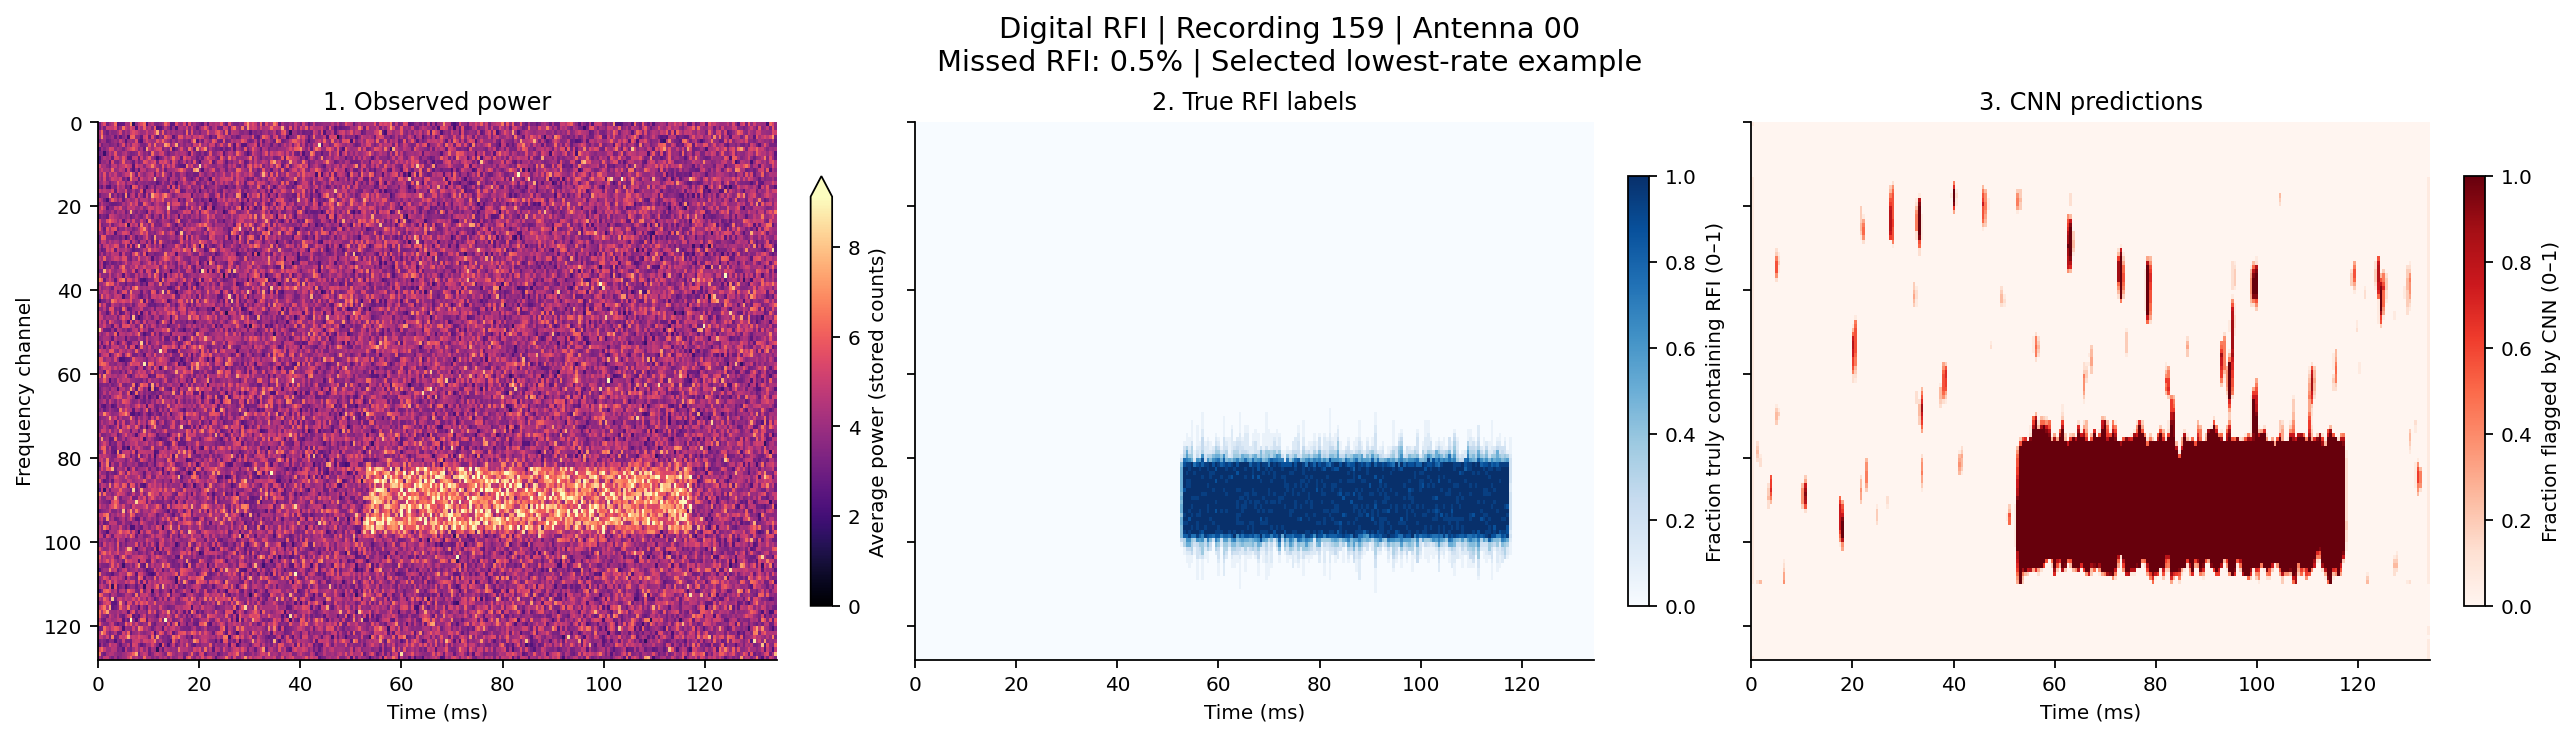

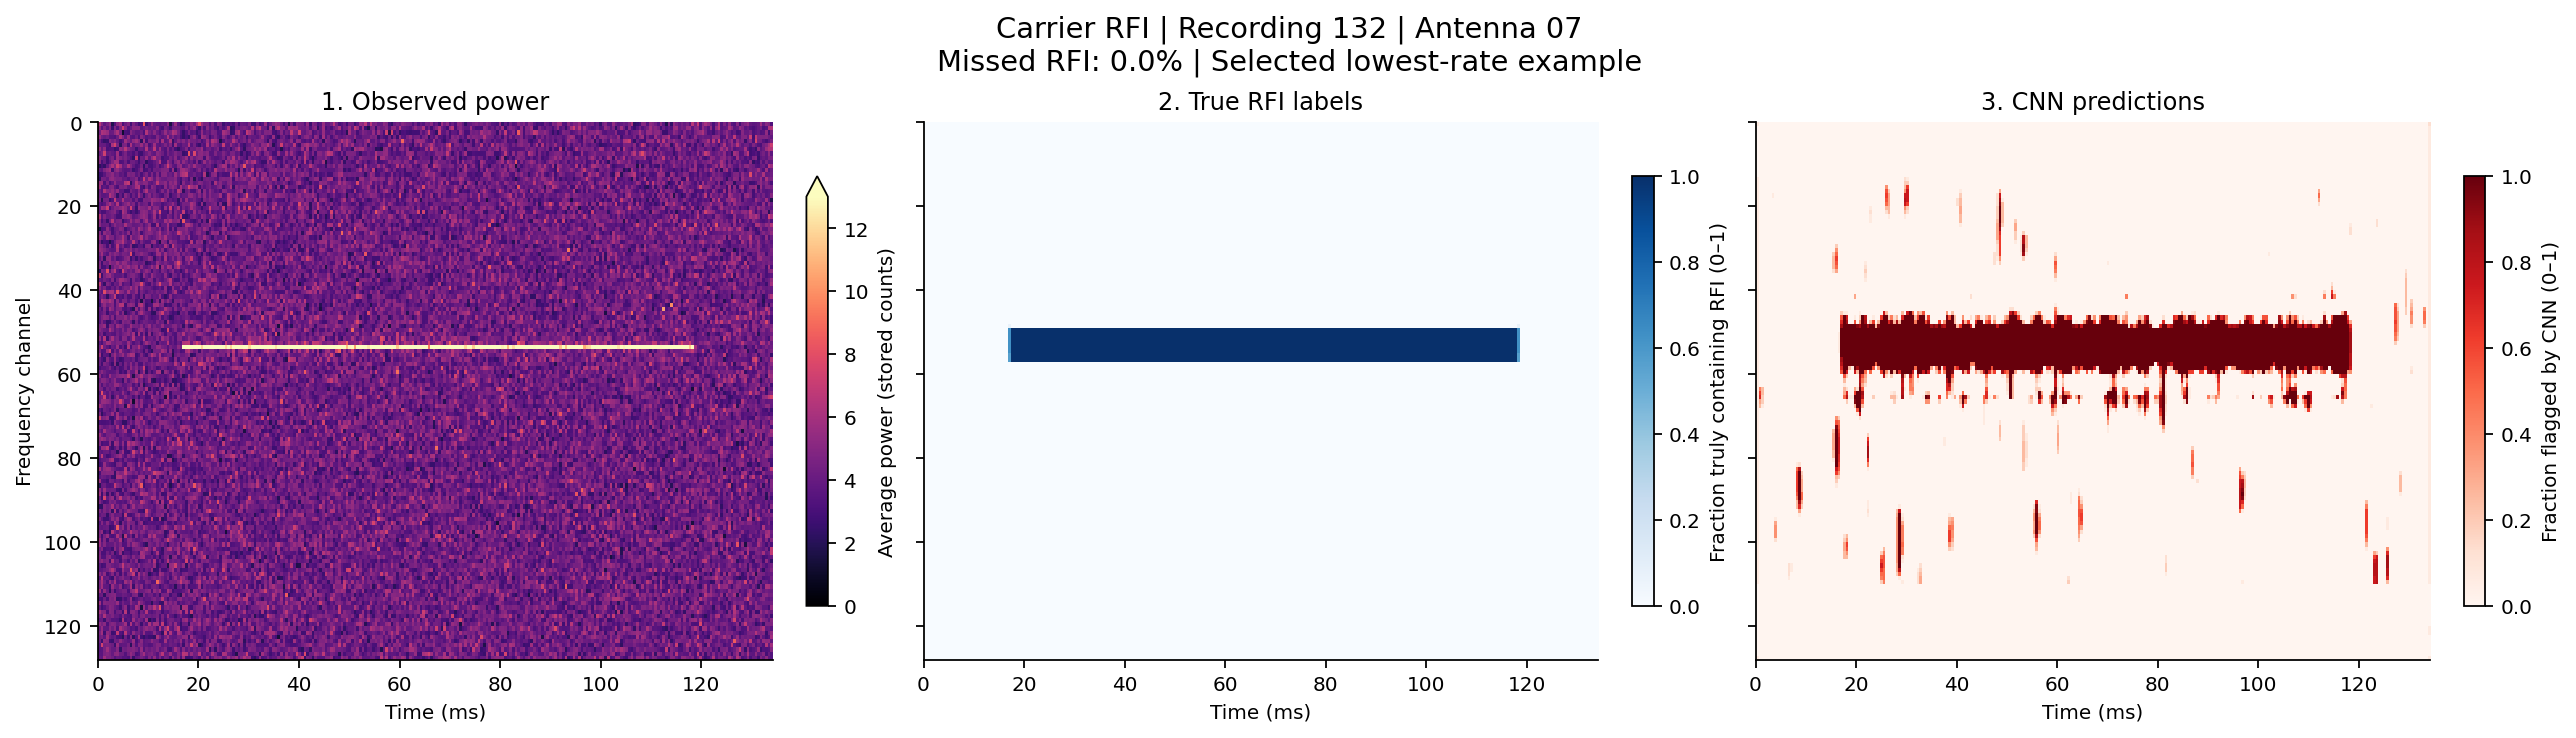

In [8]:
def average(x,factor=16):return x.reshape(-1,factor,x.shape[1]).mean(axis=1)
for e in good_examples:
    dt=e['metadata']['dt_s'];extent=[0,len(e['raw'])*dt*1000,128,0]
    fig,axes=plt.subplots(1,3,figsize=(16,4.5),sharex=True,sharey=True,layout='constrained')
    pred=e['predictions']['Baseline']
    views=[average(e['raw']),average(e['truth']),average(pred['flags'])]
    titles=['1. Observed power','2. True RFI labels','3. CNN predictions']
    vmax=np.quantile(views[0],.995)
    for j,(view,title) in enumerate(zip(views,titles)):
        im=axes[j].imshow(view.T,aspect='auto',origin='upper',extent=extent,interpolation='nearest',
                          cmap=['magma','Blues','Reds'][j],vmin=0,vmax=vmax if j==0 else 1)
        axes[j].set_title(title);axes[j].set_xlabel('Time (ms)')
        fig.colorbar(im,ax=axes[j],shrink=.8,label=['Average power (stored counts)','Fraction truly containing RFI (0–1)','Fraction flagged by CNN (0–1)'][j],
                     extend='max' if j==0 else 'neither')
    axes[0].set_ylabel('Frequency channel')
    family_name={'digital':'Digital RFI','carrier':'Carrier RFI'}[e['family']]
    selected_metric=next(r for r in good_metrics if r['sample_id']==e['sample_id'] and r['antenna']==e['antenna'])
    fig.suptitle(f"{family_name} | Recording {e['sample_id']} | Antenna {e['antenna']:02d}\nMissed RFI: {selected_metric['false_negative_rate_percent']:.1f}% | Selected lowest-rate example", fontsize=13)
    save(fig,f"{e['family']}_{e['sample_id']}_a{e['antenna']}_overview")


### Four-family comparison on a shared power scale

Each row shows the lowest-false-negative-rate example **within that family**. These are selected favorable cases, not typical cases. Compare how closely the red flag structures follow the blue label structures. All power panels share the same range, chosen as the maximum of the examples' 99.5th-percentile displayed powers; values above it are color-clipped. Each label/flag display pixel is a fraction of 16 native samples, not confidence.


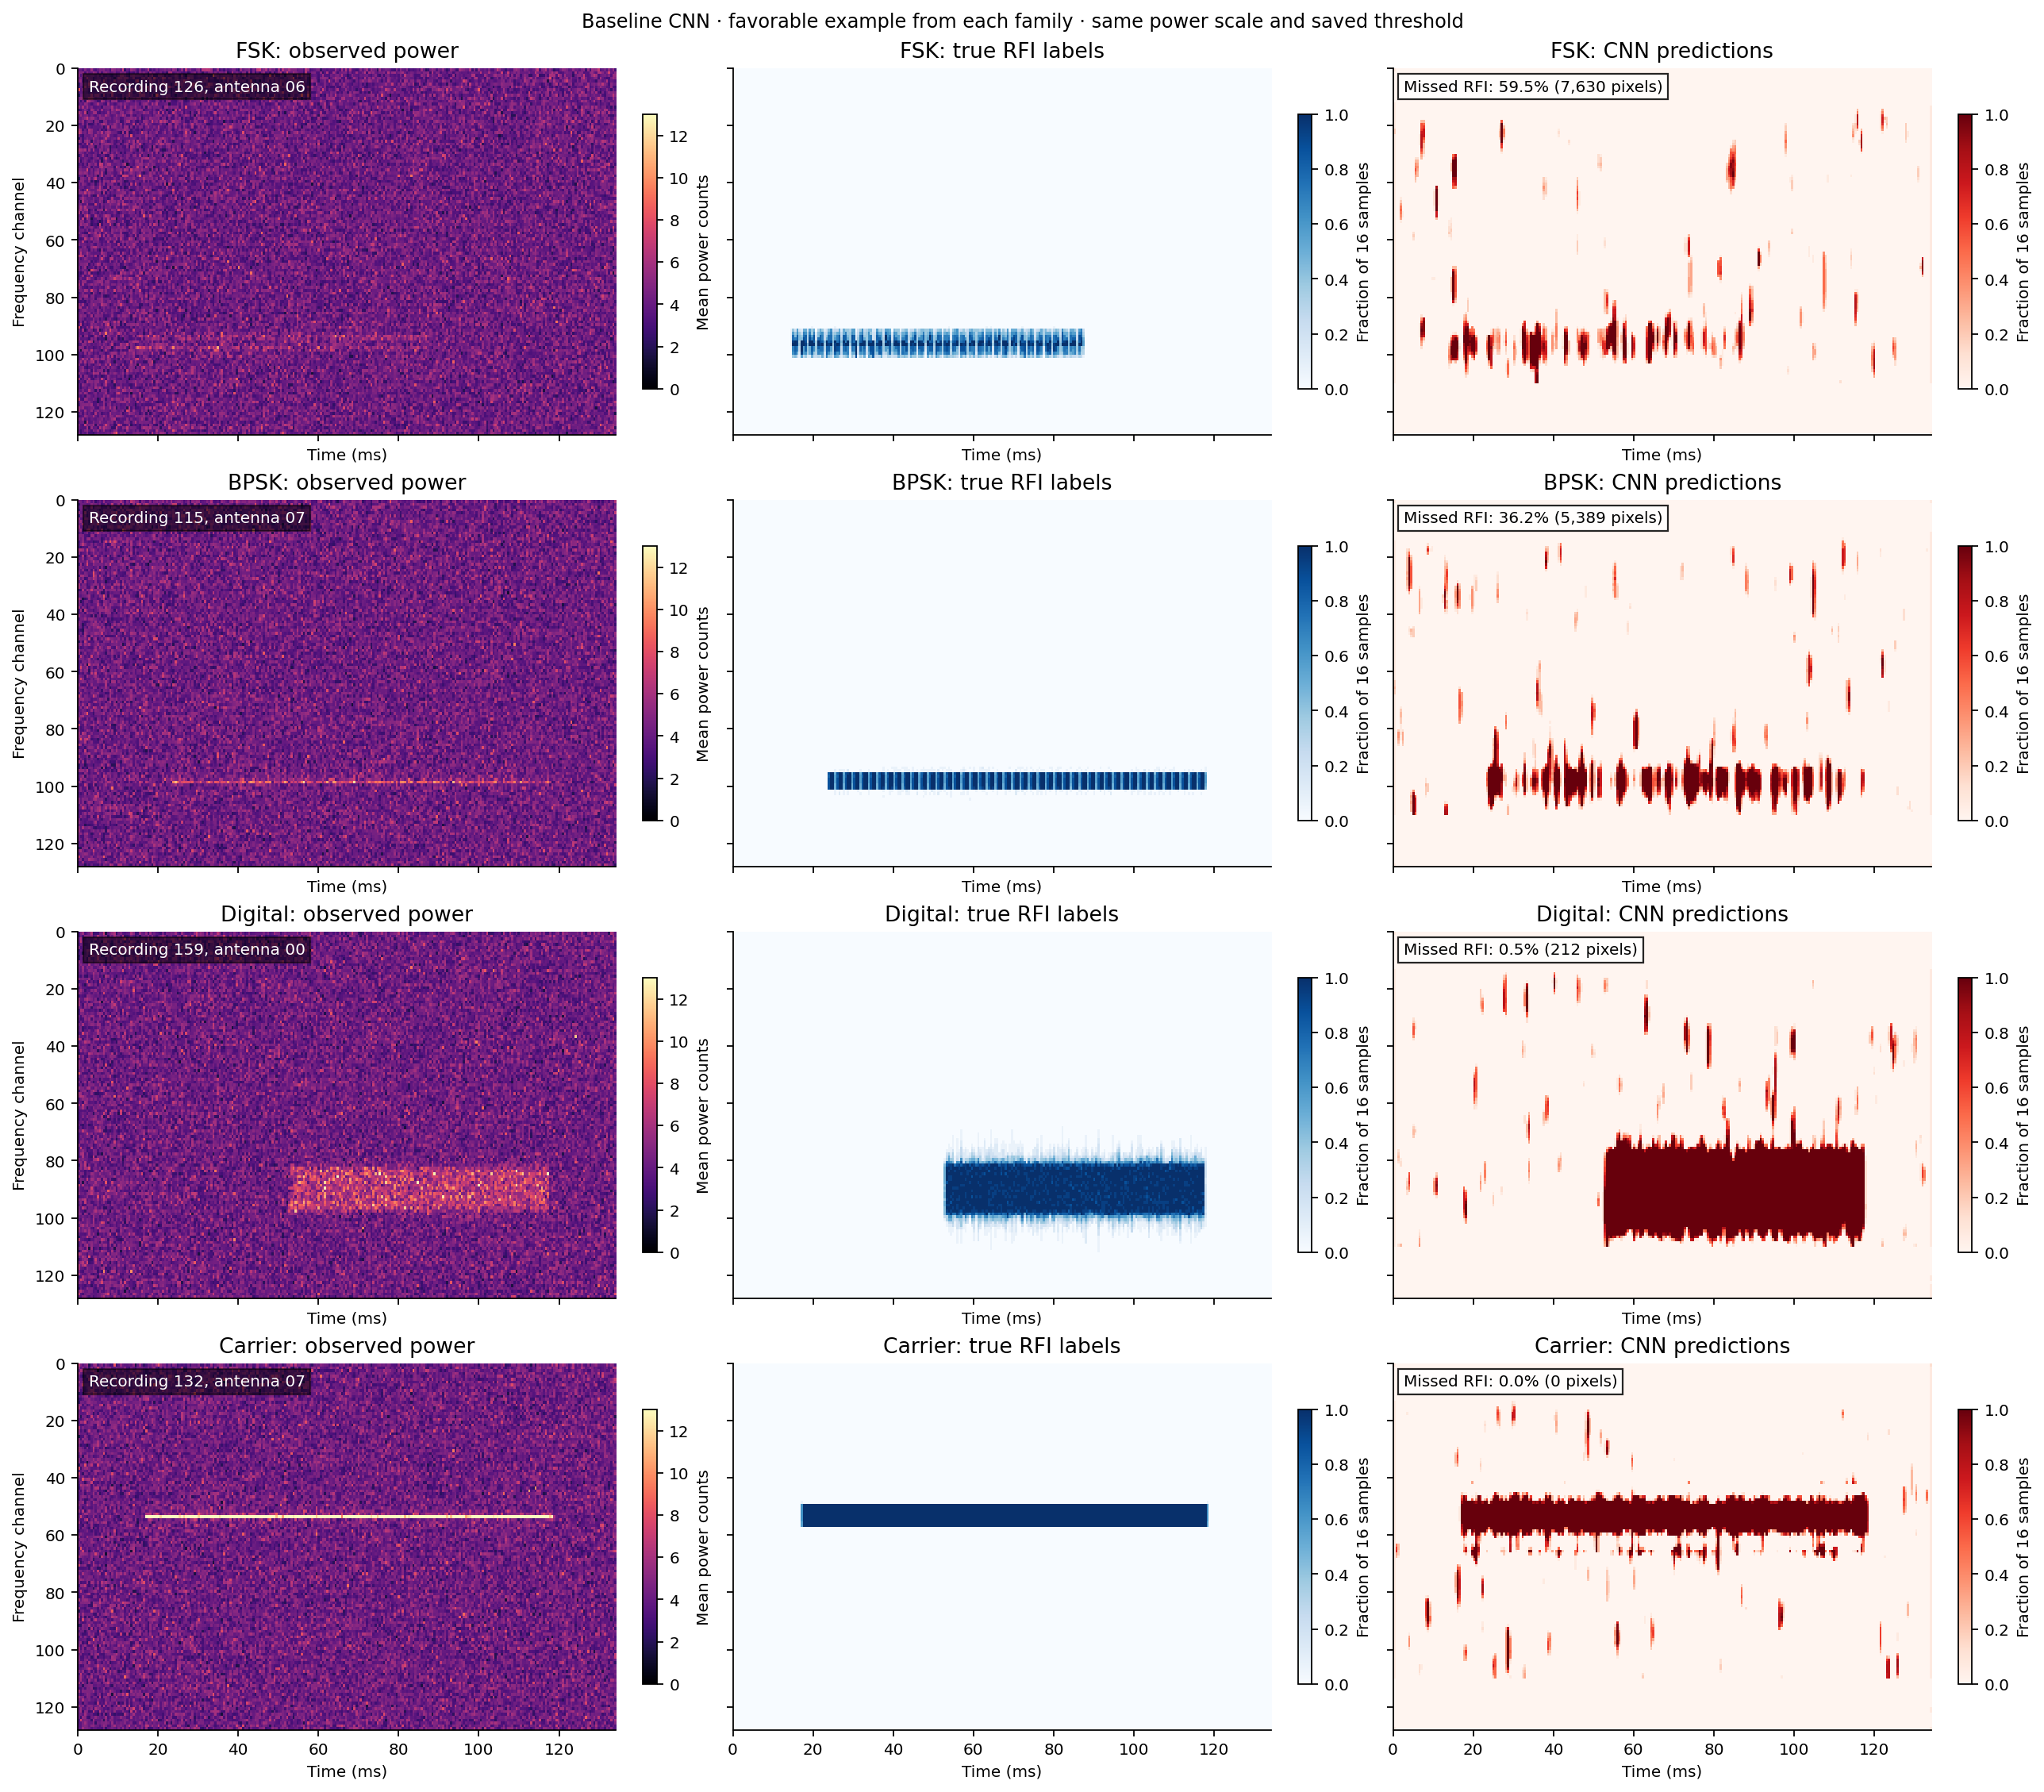

In [9]:
comparison_examples=[next(e for e in examples+good_examples
                         if e['family']==family and e['selection']=='Lowest false negative rate')
                     for family in ['fsk','bpsk']+good_families]
shared_vmax=max(float(np.quantile(average(e['raw']),.995)) for e in comparison_examples)
fig,axes=plt.subplots(4,3,figsize=(16,14),sharex=True,sharey=True,layout='constrained')
for i,e in enumerate(comparison_examples):
    extent=[0,len(e['raw'])*e['metadata']['dt_s']*1000,128,0]
    views=[average(e['raw']),average(e['truth']),average(e['predictions']['Baseline']['flags'])]
    for j,view in enumerate(views):
        im=axes[i,j].imshow(view.T,aspect='auto',origin='upper',extent=extent,interpolation='nearest',
                            cmap=['magma','Blues','Reds'][j],vmin=0,vmax=shared_vmax if j==0 else 1)
        axes[i,j].set_xlabel('Time (ms)')
        fig.colorbar(im,ax=axes[i,j],shrink=.75,label='Mean power counts' if j==0 else 'Fraction of 16 samples')
        family_name={'fsk':'FSK','bpsk':'BPSK','digital':'Digital','carrier':'Carrier'}[e['family']]
        axes[i,j].set_title(f"{family_name}: "+['observed power','true RFI labels','CNN predictions'][j], fontsize=12)
    selected_metric=next(r for r in metrics+good_metrics if r['sample_id']==e['sample_id'] and r['antenna']==e['antenna'])
    axes[i,0].set_ylabel('Frequency channel')
    axes[i,0].text(0.02, 0.97, f"Recording {e['sample_id']}, antenna {e['antenna']:02d}", transform=axes[i,0].transAxes, va='top', color='white', fontsize=9, bbox=dict(facecolor='black',alpha=.5,pad=3))
    axes[i,2].text(0.02, 0.97, f"Missed RFI: {selected_metric['false_negative_rate_percent']:.1f}% ({selected_metric['fn']:,} pixels)", transform=axes[i,2].transAxes, va='top', fontsize=9, bbox=dict(facecolor='white',alpha=.85,pad=3))
fig.suptitle('Baseline CNN · favorable example from each family · same power scale and saved threshold')
save(fig,'four_family_false_negative_comparison')


### What this comparison can tell us

Digital and carrier have much higher family-level AP and recall than FSK/BPSK in this validation run. Check whether their labeled time/frequency structures are more consistently reproduced in the prediction panel. Brightness alone is not a label: noisy measured power and injected-power labels differ. The figures do not establish whether signal strength, shape or training caused the performance difference. They also do not imply every digital/carrier recording is easy.
